# Session 2: Programming Language Constructs

Diploma in AI · companion notebook

Prepared by **Hamna Zahid Khan**, Junior Lecturer

Run each cell from top to bottom. In Colab, the first cell installs anything that is missing.

In [1]:
import os, sys, subprocess
try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q'] + ['flask', 'requests', 'beautifulsoup4', 'lxml', 'scikit-learn', 'seaborn'], check=False)
    # fetch helper/data files used by the examples
    base = 'https://raw.githubusercontent.com/Hamnakhan123/Diploma-in-AI/main/term-1/04-application-based-programming-in-python/code/'
    for f in []:
        if not os.path.exists(f):
            os.makedirs(os.path.dirname(f) or '.', exist_ok=True)
            subprocess.run(['wget', '-q', '-O', f, base + f], check=False)
print('ready')

ready


## Example: `session-02_data_types.py`

In [2]:
"""
Session 2 · Example 1: Python's built-in data types and conversions
-------------------------------------------------------------------
Run:  python session-02_data_types.py
"""
samples = {
    "int": 42,
    "float": 3.75,
    "complex": 2 + 3j,
    "bool": True,
    "str": "Karachi",
    "list": [85, 90, 78],
    "tuple": (24.86, 67.01),          # latitude, longitude
    "set": {"python", "sql", "python"},
    "dict": {"name": "Ali", "cgpa": 3.4},
    "NoneType": None,
}
print(f"{'type':9} {'value':28} {'mutable?':9} {'ordered?':9}")
mutable = {"list", "set", "dict"}
ordered = {"str", "list", "tuple", "dict"}
for name, value in samples.items():
    shown = "{" + ", ".join(map(repr, sorted(value))) + "}" if isinstance(value, set) else str(value)  # sets have no order: sort for a stable display
    print(f"{type(value).__name__:9} {shown:28} {str(name in mutable):9} {str(name in ordered):9}")

# Numbers
print("\n7 / 2 =", 7 / 2, "| 7 // 2 =", 7 // 2, "| 2 ** 100 has", len(str(2 ** 100)), "digits")
print("0.1 + 0.2 =", 0.1 + 0.2, "-> use round() or decimal for money:", round(0.1 + 0.2, 2))
print("complex parts:", samples["complex"].real, samples["complex"].imag)

# bool is a subclass of int; 'truthiness' of values
print("True + True =", True + True)
for v in [0, 1, "", "0", [], [0], None, 0.0]:
    print(f"  bool({v!r:5}) = {bool(v)}")

# Strings are sequences
s = "Diploma in AI"
print("\nindex/slice:", s[0], s[-2:], s[:7], "| upper:", s.upper(), "| words:", s.split())

# Explicit conversion (casting)
print("\nint('42') + 1 =", int("42") + 1)
print("float('3.5') * 2 =", float("3.5") * 2)
print("int(9.99) =", int(9.99), "(truncates, does not round)")
print("str(2026) + '!' =", str(2026) + "!")
print("list('abc') =", list("abc"), "| tuple([1, 2]) =", tuple([1, 2]), "| set([1, 1, 2]) =", set([1, 1, 2]))
print("dict([('a', 1), ('b', 2)]) =", dict([("a", 1), ("b", 2)]))
try:
    int("12.5")
except ValueError as e:
    print("int('12.5') fails:", e)

type      value                        mutable?  ordered? 
int       42                           False     False    
float     3.75                         False     False    
complex   (2+3j)                       False     False    
bool      True                         False     False    
str       Karachi                      False     True     
list      [85, 90, 78]                 True      True     
tuple     (24.86, 67.01)               False     True     
set       {'python', 'sql'}            True      False    
dict      {'name': 'Ali', 'cgpa': 3.4} True      True     
NoneType  None                         False     False    

7 / 2 = 3.5 | 7 // 2 = 3 | 2 ** 100 has 31 digits
0.1 + 0.2 = 0.30000000000000004 -> use round() or decimal for money: 0.3
complex parts: 2.0 3.0
True + True = 2
  bool(0    ) = False
  bool(1    ) = True
  bool(''   ) = False
  bool('0'  ) = True
  bool([]   ) = False
  bool([0]  ) = True
  bool(None ) = False
  bool(0.0  ) = False

index/slice: D

## Example: `session-02_operators.py`

In [3]:
"""
Session 2 · Example 2: every family of operators, plus precedence
-----------------------------------------------------------------
Run:  python session-02_operators.py
"""
a, b = 17, 5
print("Arithmetic")
for sym, val in [("+", a + b), ("-", a - b), ("*", a * b), ("/", a / b),
                 ("//", a // b), ("%", a % b), ("**", a ** b)]:
    print(f"  {a} {sym:2} {b} = {val}")
print("  negative floor division: -17 // 5 =", -17 // 5, "and -17 % 5 =", -17 % 5)

print("\nComparison (always give a bool)")
print("  17 > 5:", a > b, "| 17 == 17.0:", 17 == 17.0, "| 'apple' < 'banana':", "apple" < "banana")
print("  chained: 0 <= 72 <= 100 ->", 0 <= 72 <= 100)

print("\nLogical (short-circuit)")
age, has_cnic = 19, False
print("  age >= 18 and has_cnic:", age >= 18 and has_cnic)
print("  age >= 18 or has_cnic:", age >= 18 or has_cnic)
print("  not has_cnic:", not has_cnic)
print("  'and'/'or' return an operand: '' or 'guest' ->", "" or "guest", "| 0 and 1/0 ->", 0 and 1 / 0)

print("\nAssignment operators")
x = 10
x += 5;  print("  x += 5  ->", x)
x -= 3;  print("  x -= 3  ->", x)
x *= 2;  print("  x *= 2  ->", x)
x //= 4; print("  x //= 4 ->", x)
x **= 2; print("  x **= 2 ->", x)
x %= 7;  print("  x %= 7  ->", x)

print("\nBitwise (on the binary form)")
p, q = 12, 10          # 1100 and 1010
print(f"  {p:04b} & {q:04b} = {p & q:04b} ({p & q})")
print(f"  {p:04b} | {q:04b} = {p | q:04b} ({p | q})")
print(f"  {p:04b} ^ {q:04b} = {p ^ q:04b} ({p ^ q})")
print(f"  {p} << 1 = {p << 1}, {p} >> 2 = {p >> 2}, ~{p} = {~p}")

print("\nMembership and identity")
skills = ["python", "sql", "git"]
print("  'sql' in skills:", "sql" in skills, "| 'java' not in skills:", "java" not in skills)
print("  'AI' in 'Diploma in AI':", "AI" in "Diploma in AI", "| key in dict:", "cgpa" in {"cgpa": 3.1})
m1 = [1, 2]; m2 = [1, 2]
print("  m1 == m2:", m1 == m2, "| m1 is m2:", m1 is m2, "| x is None:", x is None)

print("\nPrecedence: ** > unary - > * / // % > + - > comparisons > not > and > or")
print("  2 + 3 * 4 ** 2 =", 2 + 3 * 4 ** 2)
print("  -3 ** 2 =", -3 ** 2, " vs (-3) ** 2 =", (-3) ** 2)
print("  not True or True =", not True or True, " vs not (True or True) =", not (True or True))
print("  2 ** 3 ** 2 =", 2 ** 3 ** 2, "(right-to-left)")

Arithmetic
  17 +  5 = 22
  17 -  5 = 12
  17 *  5 = 85
  17 /  5 = 3.4
  17 // 5 = 3
  17 %  5 = 2
  17 ** 5 = 1419857
  negative floor division: -17 // 5 = -4 and -17 % 5 = 3

Comparison (always give a bool)
  17 > 5: True | 17 == 17.0: True | 'apple' < 'banana': True
  chained: 0 <= 72 <= 100 -> True

Logical (short-circuit)
  age >= 18 and has_cnic: False
  age >= 18 or has_cnic: True
  not has_cnic: True
  'and'/'or' return an operand: '' or 'guest' -> guest | 0 and 1/0 -> 0

Assignment operators
  x += 5  -> 15
  x -= 3  -> 12
  x *= 2  -> 24
  x //= 4 -> 6
  x **= 2 -> 36
  x %= 7  -> 1

Bitwise (on the binary form)
  1100 & 1010 = 1000 (8)
  1100 | 1010 = 1110 (14)
  1100 ^ 1010 = 0110 (6)
  12 << 1 = 24, 12 >> 2 = 3, ~12 = -13

Membership and identity
  'sql' in skills: True | 'java' not in skills: True
  'AI' in 'Diploma in AI': True | key in dict: True
  m1 == m2: True | m1 is m2: False | x is None: False

Precedence: ** > unary - > * / // % > + - > comparisons > not > and >

## Example: `session-02_control_flow.py`

In [4]:
"""
Session 2 · Example 3: decisions and loops
------------------------------------------
Run:  python session-02_control_flow.py
"""
# 1. if / elif / else : the first true branch wins
def grade(mark):
    if mark >= 85:
        return "A"
    elif mark >= 70:
        return "B"
    elif mark >= 55:
        return "C"
    else:
        return "F"
print("grades:", {m: grade(m) for m in [92, 85, 71, 40]})

# Conditional expression (one-line if)
temp = 38
print("weather:", "hot" if temp > 35 else "pleasant")

# 2. match / case (Python 3.10+): compare a value against patterns
def command(text):
    match text.split():
        case ["add", item]:
            return f"adding {item}"
        case ["remove", item]:
            return f"removing {item}"
        case ["list"]:
            return "listing all items"
        case _:
            return "unknown command"
for c in ["add milk", "remove eggs", "list", "fly away"]:
    print(f"  {c!r:14} -> {command(c)}")

# 3. for loop over a sequence, with enumerate and zip
students = ["Ali", "Sana", "Bilal"]
marks = [78, 91, 64]
for rank, (name, m) in enumerate(sorted(zip(students, marks), key=lambda t: -t[1]), start=1):
    print(f"  #{rank} {name:6} {m}")

# range(start, stop, step): stop is excluded
print("range(1, 11, 3):", list(range(1, 11, 3)), "| countdown:", list(range(5, 0, -1)))

# 4. while loop: repeat until a condition fails
balance, months = 50_000, 0
while balance < 100_000:          # savings grow 2 % per month
    balance *= 1.02
    months += 1
print(f"Rs 50,000 doubles at 2%/month after {months} months (Rs {balance:,.0f})")

# 5. break, continue, pass and the loop 'else'
for n in range(2, 30):
    if n % 2 == 0:
        continue                  # skip even numbers
    for d in range(3, int(n ** 0.5) + 1, 2):
        if n % d == 0:
            break                 # not prime: leave the inner loop
    else:
        print(n, end=" ")         # runs only if the inner loop did NOT break
print("<- odd primes below 30")

def todo():
    pass                          # placeholder: a block cannot be empty

# 6. Nested loops: a multiplication grid
for i in range(1, 4):
    print("  " + " ".join(f"{i * j:3}" for j in range(1, 6)))

# 7. Comprehensions: a loop that builds a collection in one expression
squares = [n * n for n in range(1, 8)]
evens = [n for n in squares if n % 2 == 0]
lengths = {name: len(name) for name in students}
print("squares:", squares, "| even squares:", evens, "| lengths:", lengths)

grades: {92: 'A', 85: 'A', 71: 'B', 40: 'F'}
weather: hot
  'add milk'     -> adding milk
  'remove eggs'  -> removing eggs
  'list'         -> listing all items
  'fly away'     -> unknown command
  #1 Sana   91
  #2 Ali    78
  #3 Bilal  64
range(1, 11, 3): [1, 4, 7, 10] | countdown: [5, 4, 3, 2, 1]
Rs 50,000 doubles at 2%/month after 36 months (Rs 101,994)
3 5 7 11 13 17 19 23 29 <- odd primes below 30
    1   2   3   4   5
    2   4   6   8  10
    3   6   9  12  15
squares: [1, 4, 9, 16, 25, 36, 49] | even squares: [4, 16, 36] | lengths: {'Ali': 3, 'Sana': 4, 'Bilal': 5}


## Example: `session-02_problem_electricity_bill.py`

In [5]:
"""
Session 2 · Real-life problem: slab-based electricity bill
-----------------------------------------------------------
PROBLEM
Electricity in many cities is billed in SLABS: the first units are cheap and
each extra block costs more. Using the ILLUSTRATIVE tariff below (made-up
rates for practice, not an official tariff), write a program that:
  1. computes the energy charge slab by slab,
  2. adds a fixed meter rent and 17 % tax on the energy charge,
  3. applies a 5 % late surcharge if paid after the due date,
  4. prints an itemised bill for several households and draws a chart of
     bill amount against units used.

SOLUTION: data types, operators, if/elif/else, for and while loops.
Run:  python session-02_problem_electricity_bill.py
"""
SLABS = [            # (units in this slab, rate per unit in Rs); None = no upper limit
    (100, 22.0),
    (100, 28.5),
    (100, 34.0),
    (None, 42.0),
]
METER_RENT = 150
TAX = 0.17
LATE = 0.05

def energy_charge(units, verbose=False):
    """Walk through the slabs, charging each block at its own rate."""
    remaining, charge, start = units, 0.0, 0
    for size, rate in SLABS:
        if remaining <= 0:
            break
        used = remaining if size is None else min(remaining, size)
        if verbose:
            print(f"    units {start + 1:>3}-{start + used:<3} x Rs {rate:5.2f} = Rs {used * rate:9,.2f}")
        charge += used * rate
        remaining -= used
        start += used
    return charge

def bill(units, late=False, verbose=False):
    energy = energy_charge(units, verbose)
    total = energy + energy * TAX + METER_RENT
    if late:
        total *= 1 + LATE
    return energy, total

households = [("Flat A-12", 85, False), ("House 47", 260, False), ("Shop 3", 410, True)]
for name, units, late in households:
    print(f"{name}: {units} units{' (paid late)' if late else ''}")
    energy, total = bill(units, late, verbose=True)
    print(f"    energy Rs {energy:,.2f} + tax Rs {energy * TAX:,.2f} + rent Rs {METER_RENT}"
          f"{' + 5% late' if late else ''} = Rs {total:,.0f}\n")

# How many units can a family use if the budget is Rs 8,000? (while loop search)
units = 0
while bill(units + 1)[1] <= 8_000:
    units += 1
print(f"Max units within a Rs 8,000 budget: {units} (bill Rs {bill(units)[1]:,.0f})")

# Chart: the bill is piecewise linear and gets steeper at each slab boundary
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
xs = list(range(0, 501, 5))
ys = [bill(u)[1] for u in xs]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(xs, ys, color="#FF6B1A", lw=2.5)
for edge in (100, 200, 300):
    ax.axvline(edge, color="#A78BFA", ls="--", lw=1)
ax.set_xlabel("Units used in the month"); ax.set_ylabel("Total bill (Rs)")
ax.set_title("Slab tariff: each extra unit costs more after every boundary")
fig.tight_layout(); fig.savefig("session-02_problem_electricity_bill.png", dpi=110)
print("Chart saved: session-02_problem_electricity_bill.png")

Flat A-12: 85 units
    units   1-85  x Rs 22.00 = Rs  1,870.00
    energy Rs 1,870.00 + tax Rs 317.90 + rent Rs 150 = Rs 2,338

House 47: 260 units
    units   1-100 x Rs 22.00 = Rs  2,200.00
    units 101-200 x Rs 28.50 = Rs  2,850.00
    units 201-260 x Rs 34.00 = Rs  2,040.00
    energy Rs 7,090.00 + tax Rs 1,205.30 + rent Rs 150 = Rs 8,445

Shop 3: 410 units (paid late)
    units   1-100 x Rs 22.00 = Rs  2,200.00
    units 101-200 x Rs 28.50 = Rs  2,850.00
    units 201-300 x Rs 34.00 = Rs  3,400.00
    units 301-410 x Rs 42.00 = Rs  4,620.00
    energy Rs 13,070.00 + tax Rs 2,221.90 + rent Rs 150 + 5% late = Rs 16,214

Max units within a Rs 8,000 budget: 248 (bill Rs 7,968)


Chart saved: session-02_problem_electricity_bill.png


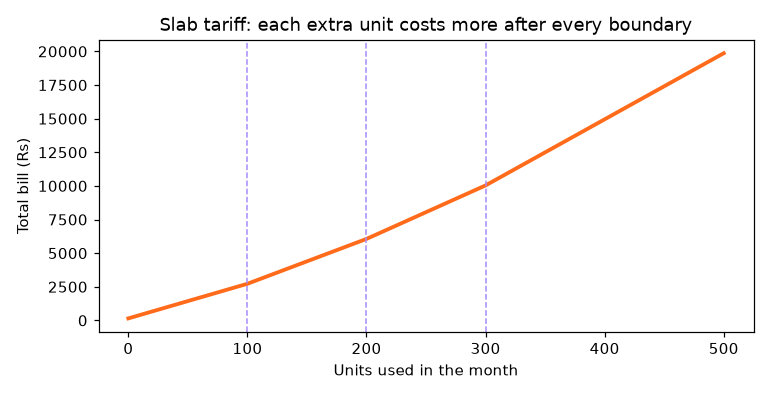

In [6]:
from IPython.display import Image, display
display(Image(filename='session-02_problem_electricity_bill.png'))  # chart saved by the cell above

## Example: `session-02_project_atm.py`

In [7]:
"""
Session 2 · Mini project: menu-driven ATM simulator
---------------------------------------------------
A classic console program that combines every construct of the session:
data types (dict, list, float), operators, if/elif/else, match/case,
while loops with break/continue, and input validation.
Inputs are scripted so the program runs unattended; replace `next_input`
with `input` to play it yourself.
Run:  python session-02_project_atm.py
"""
PIN = "4321"
DAILY_LIMIT = 50_000
NOTES = [5000, 1000, 500]          # notes the machine can dispense

account = {"holder": "Sana Tariq", "balance": 82_500.0, "withdrawn_today": 0}
history = []

scripted = iter(["1111", "4321",           # wrong PIN, then right PIN
                 "1", "2", "12500", "2", "7300", "3", "5000", "2", "60000", "4", "9", "5"])
def next_input(prompt):
    value = next(scripted)
    print(prompt + value)
    return value

def dispense(amount):
    """Greedy split of an amount into notes; returns dict or None if impossible."""
    plan = {}
    for note in NOTES:
        plan[note], amount = divmod(amount, note)
    return None if amount else {n: c for n, c in plan.items() if c}

# ---- login: three attempts ----
for attempt in range(1, 4):
    if next_input("Enter PIN: ") == PIN:
        print(f"Welcome, {account['holder']}!\n")
        break
    print(f"  wrong PIN ({3 - attempt} attempts left)")
else:
    raise SystemExit("Card retained. Please contact your branch.")

# ---- main menu ----
while True:
    choice = next_input("[1] Balance [2] Withdraw [3] Deposit [4] Mini statement [5] Exit > ")
    match choice:
        case "1":
            print(f"  Balance: Rs {account['balance']:,.2f}")
        case "2":
            amount = int(next_input("  Amount: "))
            if amount % 500:
                print("  Amount must be a multiple of 500"); continue
            if amount > account["balance"]:
                print("  Insufficient balance"); continue
            if account["withdrawn_today"] + amount > DAILY_LIMIT:
                print(f"  Daily limit Rs {DAILY_LIMIT:,} exceeded"); continue
            notes = dispense(amount)
            account["balance"] -= amount
            account["withdrawn_today"] += amount
            history.append(("withdraw", -amount))
            print("  Dispensed:", ", ".join(f"{c} x Rs {n}" for n, c in notes.items()))
        case "3":
            amount = float(next_input("  Deposit amount: "))
            account["balance"] += amount
            history.append(("deposit", amount))
            print(f"  Deposited Rs {amount:,.2f}")
        case "4":
            for kind, amt in history[-5:]:
                print(f"  {kind:9} {amt:+12,.2f}")
            print(f"  {'balance':9} {account['balance']:12,.2f}")
        case "5":
            print("Thank you. Please take your card.")
            break
        case _:
            print("  Invalid option, choose 1-5")

Enter PIN: 1111
  wrong PIN (2 attempts left)
Enter PIN: 4321
Welcome, Sana Tariq!

[1] Balance [2] Withdraw [3] Deposit [4] Mini statement [5] Exit > 1
  Balance: Rs 82,500.00
[1] Balance [2] Withdraw [3] Deposit [4] Mini statement [5] Exit > 2
  Amount: 12500
  Dispensed: 2 x Rs 5000, 2 x Rs 1000, 1 x Rs 500
[1] Balance [2] Withdraw [3] Deposit [4] Mini statement [5] Exit > 2
  Amount: 7300
  Amount must be a multiple of 500
[1] Balance [2] Withdraw [3] Deposit [4] Mini statement [5] Exit > 3
  Deposit amount: 5000
  Deposited Rs 5,000.00
[1] Balance [2] Withdraw [3] Deposit [4] Mini statement [5] Exit > 2
  Amount: 60000
  Daily limit Rs 50,000 exceeded
[1] Balance [2] Withdraw [3] Deposit [4] Mini statement [5] Exit > 4
  withdraw    -12,500.00
  deposit      +5,000.00
  balance      75,000.00
[1] Balance [2] Withdraw [3] Deposit [4] Mini statement [5] Exit > 9
  Invalid option, choose 1-5
[1] Balance [2] Withdraw [3] Deposit [4] Mini statement [5] Exit > 5
Thank you. Please take y